In [1]:
from cyvcf2 import VCF

vcf = VCF("/Volumes/mac1/data/limb/finn-b-Q17_OTHER_CONGEN_MALFO_LIMBS.vcf.gz")

# Afficher l'en-tête complet
print(vcf.raw_header)

# Afficher les colonnes (samples)
print("Colonnes :", vcf.samples)


##fileformat=VCFv4.2
##FILTER=<ID=PASS,Description="All filters passed">
##INFO=<ID=AF,Number=A,Type=Float,Description="Allele Frequency">
##FORMAT=<ID=ES,Number=A,Type=Float,Description="Effect size estimate relative to the alternative allele">
##FORMAT=<ID=SE,Number=A,Type=Float,Description="Standard error of effect size estimate">
##FORMAT=<ID=LP,Number=A,Type=Float,Description="-log10 p-value for effect estimate">
##FORMAT=<ID=AF,Number=A,Type=Float,Description="Alternate allele frequency in the association study">
##FORMAT=<ID=SS,Number=A,Type=Integer,Description="Sample size used to estimate genetic effect">
##FORMAT=<ID=EZ,Number=A,Type=Float,Description="Z-score provided if it was used to derive the EFFECT and SE fields">
##FORMAT=<ID=SI,Number=A,Type=Float,Description="Accuracy score of summary data imputation">
##FORMAT=<ID=NC,Number=A,Type=Integer,Description="Number of cases used to estimate genetic effect">
##FORMAT=<ID=ID,Number=1,Type=String,Description="Study variant id

In [2]:
from cyvcf2 import VCF
import pandas as pd

vcf_path = "/Volumes/mac1/data/limb/finn-b-Q17_OTHER_CONGEN_MALFO_LIMBS.vcf.gz"
vcf = VCF(vcf_path)

def get_value(variant, field):
    """Retourne une valeur simple (float/int) ou None."""
    try:
        arr = variant.format(field)
        if arr is None:
            return None
        val = arr[0]
        # si val est un tableau numpy, prendre val[0]
        if hasattr(val, "__len__") and not isinstance(val, (str, bytes)):
            return val[0]
        return val
    except:
        return None

records = []

for variant in vcf:
    ES = get_value(variant, "ES")
    SE = get_value(variant, "SE")
    LP = get_value(variant, "LP")
    AF = get_value(variant, "AF")
    SS = get_value(variant, "SS")
    NC = get_value(variant, "NC")

    if LP is not None and LP > 5:
        records.append({
            "CHROM": variant.CHROM,
            "POS": variant.POS,
            "ID": variant.ID,
            "REF": variant.REF,
            "ALT": variant.ALT[0],
            "ES": ES,
            "SE": SE,
            "LP": LP,
            "AF": AF,
            "SS": SS,
            "NC": NC
        })

df = pd.DataFrame(records)
df.to_csv("/Volumes/mac1/data/limb/limb_significant_variants_clean.csv", index=False)

print(df.head())
print("Nombre de variants significatifs :", len(df))


  CHROM       POS           ID REF ALT      ES      SE       LP        AF  \
0     1  14605948   rs75914458   A   G  7.8193  1.7421  5.14442  0.004535   
1     1  14614858  rs147770579   T   C  8.1951  1.8070  5.24003  0.004373   
2     1  14616891  rs140845648   A   G  8.1970  1.8073  5.24048  0.004374   
3     1  22204154  rs181769482   C   T  6.5060  1.2476  6.73542  0.008005   
4     1  22225373  rs141061782   G   A  3.8464  0.8159  5.61547  0.014600   

     SS    NC  
0  None  None  
1  None  None  
2  None  None  
3  None  None  
4  None  None  
Nombre de variants significatifs : 120


In [3]:
#Trier les variants par significativité
df.sort_values("LP", ascending=False).head(20)


,CHROM,POS,ID,REF,ALT,ES,SE,LP,AF,SS,NC
3,1,22204154,rs181769482,C,T,6.506000,1.2476,6.73542,0.008005,None,None
9,1,152650983,rs563437346,G,A,24.494801,4.8658,6.31858,0.001394,None,None
10,1,152716199,rs188107946,A,G,24.333599,4.8389,6.30662,0.001399,None,None
83,10,3841296,rs571858373,G,A,22.645000,4.5411,6.21176,0.001514,None,None
11,1,153054385,rs116357780,G,A,21.208401,4.3171,6.04648,0.001510,None,None
43,3,2153518,rs779380194,T,C,7.447900,1.5167,6.04177,0.006176,None,None
12,1,153069482,rs538652183,T,C,20.767700,4.2442,6.00340,0.001518,None,None
13,1,153071385,rs777871070,T,TA,20.759100,4.2430,6.00205,0.001520,None,None
109,22,48930023,rs713928,A,C,-0.783200,0.1605,5.97510,0.662900,None,None
101,18,49000269,rs541047155,A,G,15.007900,3.0764,5.97102,0.001836,None,None


In [4]:
#Voir les variants avec les plus grands effets
df.sort_values("ES", ascending=False).head(20)


,CHROM,POS,ID,REF,ALT,ES,SE,LP,AF,SS,NC
51,3,193895930,rs900763390,G,T,185.477997,41.295898,5.15027,0.000143,None,None
78,7,85176227,rs527572870,A,G,83.434303,17.211500,5.90309,0.000245,None,None
119,X,150801686,rs187148118,C,T,74.054497,16.464500,5.16336,0.000213,None,None
118,X,150801527,rs189894061,A,T,74.054398,16.464500,5.16336,0.000213,None,None
114,X,150796589,rs769223365,A,C,74.000397,16.453100,5.16298,0.000213,None,None
113,X,150796583,rs749694596,T,C,74.000397,16.453100,5.16298,0.000213,None,None
117,X,150797855,rs149904168,G,T,74.000099,16.453100,5.16298,0.000213,None,None
116,X,150797738,rs747435727,C,T,74.000099,16.453100,5.16298,0.000213,None,None
115,X,150797626,rs780968876,C,G,74.000099,16.453100,5.16298,0.000213,None,None
112,X,150795127,rs141460353,A,G,73.972099,16.447100,5.16285,0.000213,None,None


In [5]:
#Voir les variants les plus fréquents
df.sort_values("AF", ascending=False).head(20)


,CHROM,POS,ID,REF,ALT,ES,SE,LP,AF,SS,NC
109,22,48930023,rs713928,A,C,-0.7832,0.1605,5.97510,0.6629,None,None
80,9,126045767,rs10739623,T,C,-0.7094,0.1594,5.07002,0.6512,None,None
82,9,126048349,rs999655,C,T,-0.7085,0.1594,5.05834,0.6512,None,None
81,9,126046024,rs10739624,C,G,-0.7080,0.1593,5.05547,0.6510,None,None
105,22,48906295,rs6007873,A,G,-0.7030,0.1535,5.33152,0.5778,None,None
108,22,48907418,rs5767178,G,T,-0.7001,0.1534,5.30181,0.5773,None,None
107,22,48906908,rs8135388,A,G,-0.7002,0.1534,5.30251,0.5773,None,None
106,22,48906678,rs8142739,C,A,-0.7000,0.1533,5.30138,0.5773,None,None
59,5,124497308,None,GAA,G,-0.6722,0.1501,5.12148,0.4773,None,None
60,5,124497316,rs34141878,T,C,-0.6722,0.1501,5.12148,0.4773,None,None


In [6]:
# assigner gene au variant intra genique
import requests

def get_gene(chrom, pos):
    url = f"https://grch37.rest.ensembl.org/overlap/region/human/{chrom}:{pos}-{pos}?feature=gene"
    r = requests.get(url, headers={"Content-Type": "application/json"})
    if not r.ok:
        return None
    data = r.json()
    if len(data) == 0:
        return None
    return data[0]["gene_id"], data[0]["external_name"]

df["GENE"] = df.apply(lambda row: get_gene(row["CHROM"], row["POS"]), axis=1)
df.to_csv("/Volumes/mac1/data/limb/limb_variants_with_genes.csv", index=False)


In [49]:
import pandas as pd
df = pd.read_csv('/Volumes/mac1/data/limb/limb_variants_with_genes.csv')
df_intra = df[~df.GENE.isna()].copy()
len(df_intra)

77

In [50]:
df_inter = df[df.GENE.isna()].copy()
len(df_inter)

43

In [9]:
df_intra.GENE = df_intra.GENE.apply(lambda x: x.split(',')[1].replace("'","").replace(")","").strip())



In [51]:
df_intra.GENE.unique()


array(["('ENSG00000142798', 'HSPG2')", "('ENSG00000219073', 'CELA3B')",
       "('ENSG00000159455', 'LCE2B')", "('ENSG00000196805', 'SPRR2B')",
       "('ENSG00000196878', 'LAMB3')", "('ENSG00000133019', 'CHRM3')",
       "('ENSG00000162849', 'KIF26B')", "('ENSG00000119778', 'ATAD2B')",
       "('ENSG00000115128', 'SF3B14')", "('ENSG00000198399', 'ITSN2')",
       "('ENSG00000115137', 'DNAJC27')", "('ENSG00000119772', 'DNMT3A')",
       "('ENSG00000138101', 'DTNB')", "('ENSG00000173567', 'GPR113')",
       "('ENSG00000135631', 'RAB11FIP5')",
       "('ENSG00000222041', 'LINC00152')",
       "('ENSG00000225258', 'AC009478.1')",
       "('ENSG00000235864', 'HSPA8P6')", "('ENSG00000115414', 'FN1')",
       "('ENSG00000237525', 'AC012668.2')",
       "('ENSG00000115694', 'STK25')", "('ENSG00000144619', 'CNTN4')",
       "('ENSG00000144724', 'PTPRG')", "('ENSG00000152580', 'IGSF10')",
       "('ENSG00000238755', 'RP11-23D24.2')",
       "('ENSG00000150471', 'LPHN3')",
       "('ENSG00000241

Code pour assigner un gène aux variants intergéniques

In [11]:
import pandas as pd
df = pd.read_csv("/Volumes/mac1/data/vep_cache/homo_sapiens/109_GRCh37/transcript_gene_tss.txt", sep="\t")
df.head()


,1,69091,ENST00000335137,ENSG00000186092,OR4F5
0,1,139379,ENST00000423372,ENSG00000237683,AL627309.1
1,1,367640,ENST00000426406,ENSG00000235249,OR4F29
2,1,622053,ENST00000332831,ENSG00000185097,OR4F16
3,1,739137,ENST00000599533,ENSG00000269831,AL669831.1
4,1,818043,ENST00000594233,ENSG00000269308,AL645608.2


# code to make genes.bed , already done
import pandas as pd

df = pd.read_csv("/Volumes/mac1/data/vep_cache/homo_sapiens/109_GRCh37/transcript_gene_tss.txt", sep="\t", header=None)
df.columns = ["Chromosome", "TSS", "Transcript", "Gene_ID", "GENE_NAME"]

genes_bed = df[["Chromosome", "TSS", "TSS", "GENE_NAME"]]
genes_bed.columns = ["Chromosome", "Start", "End", "GENE_NAME"]

genes_bed.to_csv("/Volumes/mac1/data/genes.bed", sep="\t", index=False, header=True)


In [12]:
genes_bed = pd.read_csv("/Volumes/mac1/data/genes.bed", sep="\t")
genes_bed.head()

,Chromosome,Start,End,GENE_NAME
0,1,69091,69091,OR4F5
1,1,139379,139379,AL627309.1
2,1,367640,367640,OR4F29
3,1,622053,622053,OR4F16
4,1,739137,739137,AL669831.1


In [13]:
import pyranges as pr

# Charger les gènes
genes = pr.read_bed("/Volumes/mac1/data/genes.bed")

# Préparer les variants intergéniques
df_inter2 = df_inter.rename(columns={
    "CHROM": "Chromosome",
    "POS": "Start"
}).copy()

df_inter2["End"] = df_inter2["Start"] + 1


# Convertir en PyRanges
variants = pr.PyRanges(df_inter2)

# Trouver le gène le plus proche
nearest = variants.nearest(genes)

# Ajouter le gène trouvé
df_inter2["GENE"] = nearest.Name.values


In [14]:
df_inter2.head()

,Chromosome,Start,ID,REF,ALT,ES,SE,LP,AF,SS,NC,GENE,End
0,1,14605948,rs75914458,A,G,7.8193,1.7421,5.14442,0.004535,NaN,NaN,KAZN,14605949
1,1,14614858,rs147770579,T,C,8.1951,1.8070,5.24003,0.004373,NaN,NaN,KAZN,14614859
2,1,14616891,rs140845648,A,G,8.1970,1.8073,5.24048,0.004374,NaN,NaN,KAZN,14616892
6,1,22291122,rs114158976,G,A,3.8171,0.7870,5.90833,0.016250,NaN,NaN,CELA3B,22291123
8,1,55493197,rs1386224996,C,A,50.8436,11.3331,5.13984,0.000415,NaN,NaN,PCSK9,55493198


In [15]:
df = pd.read_csv("/Volumes/mac1/data/limb/limb_variants_with_genes.csv")
df_intra = df[~df["GENE"].isna()].copy()
df_intra.GENE = df_intra.GENE.apply(lambda x: x.split(',')[1].replace("'",'').replace(")",'').strip())
df_intra.head()

,CHROM,POS,ID,REF,ALT,ES,SE,LP,AF,SS,NC,GENE
3,1,22204154,rs181769482,C,T,6.5060,1.2476,6.73542,0.008005,NaN,NaN,HSPG2
4,1,22225373,rs141061782,G,A,3.8464,0.8159,5.61547,0.014600,NaN,NaN,HSPG2
5,1,22229352,rs148796759,C,G,3.8393,0.8154,5.60223,0.014700,NaN,NaN,HSPG2
7,1,22321162,rs190694199,C,A,4.5916,0.9870,5.48320,0.010960,NaN,NaN,CELA3B
9,1,152650983,rs563437346,G,A,24.4948,4.8658,6.31858,0.001394,NaN,NaN,LCE2B


In [16]:
df_intra.head()

,CHROM,POS,ID,REF,ALT,ES,SE,LP,AF,SS,NC,GENE
3,1,22204154,rs181769482,C,T,6.5060,1.2476,6.73542,0.008005,NaN,NaN,HSPG2
4,1,22225373,rs141061782,G,A,3.8464,0.8159,5.61547,0.014600,NaN,NaN,HSPG2
5,1,22229352,rs148796759,C,G,3.8393,0.8154,5.60223,0.014700,NaN,NaN,HSPG2
7,1,22321162,rs190694199,C,A,4.5916,0.9870,5.48320,0.010960,NaN,NaN,CELA3B
9,1,152650983,rs563437346,G,A,24.4948,4.8658,6.31858,0.001394,NaN,NaN,LCE2B


In [17]:
df_intra = df_intra.rename(columns={
    "CHROM": "Chromosome",
    "POS": "Start"
}).copy()

df_intra["End"] = df_intra["Start"] + 1

In [18]:
df_all = pd.concat([df_intra, df_inter2], ignore_index=True)


In [19]:
df_all.to_csv("/Volumes/mac1/data/limb/df_allVariantWithGeneName.csv", index=False)

In [52]:
df_all = pd.read_csv("/Volumes/mac1/data/limb/df_allVariantWithGeneName.csv")
df_all.head()

,Chromosome,Start,ID,REF,ALT,ES,SE,LP,AF,SS,NC,GENE,End
0,1,22204154,rs181769482,C,T,6.5060,1.2476,6.73542,0.008005,NaN,NaN,HSPG2,22204155
1,1,22225373,rs141061782,G,A,3.8464,0.8159,5.61547,0.014600,NaN,NaN,HSPG2,22225374
2,1,22229352,rs148796759,C,G,3.8393,0.8154,5.60223,0.014700,NaN,NaN,HSPG2,22229353
3,1,22321162,rs190694199,C,A,4.5916,0.9870,5.48320,0.010960,NaN,NaN,CELA3B,22321163
4,1,152650983,rs563437346,G,A,24.4948,4.8658,6.31858,0.001394,NaN,NaN,LCE2B,152650984


In [57]:
len(df_all)

119

In [56]:
df_all.drop(df_all[df_all.GENE == 'PIK3C2A'].index, inplace=True)

In [12]:
# motif_to_tf_human

import pandas as pd
motifs_human = pd.read_csv("/Volumes/mac1/data/TF_totonto/Human_TF_MotifList_v_1.01.csv")

# Filtrer les motifs humains valides
motifs_human_clean = motifs_human.dropna(subset=["Motif ID", "HGNC symbol", "CIS-BP ID"])

# Liste des motifs humains
human_motif_ids = set(motifs_human_clean["Motif ID"])

# Mapping motif → TF humain
motif_to_tf_human = dict(zip(
    motifs_human_clean["Motif ID"],
    motifs_human_clean["HGNC symbol"].str.upper()
))


In [66]:
import os
pwm_dir = "/Volumes/mac1/data/TF_totonto/PWMs"

def read_pwm(path):
    pwm = []
    with open(path) as f:
        lines = f.readlines()
        for line in lines:
            parts = line.strip().split()
            if len(parts) == 4:
                pwm.append([float(x) for x in parts])
    return pwm

motif_pwm_dict = {}

motif_to_pwmFile = dict(zip(
    motifs_human_clean["Motif ID"],
    motifs_human_clean["CIS-BP ID"]
))
introuvable = 0
for motif_id in human_motif_ids:
    pwm_file = os.path.join(pwm_dir, motif_to_pwmFile[motif_id] + ".txt")
    if os.path.exists(pwm_file):
        motif_pwm_dict[motif_id] = read_pwm(pwm_file)
    else:
        introuvable += 1
print('introuvables =', introuvable)

introuvables = 1125


In [ ]:
#already done
#def write_meme_file(motif_pwm_dict, output_path):
    with open(output_path, "w") as f:
        f.write("MEME version 4\n\n")
        f.write("ALPHABET= ACGT\n\n")
        f.write("strands: + -\n\n")
        f.write("Background letter frequencies:\n")
        f.write("A 0.25 C 0.25 G 0.25 T 0.25\n\n")

        for motif_id, pwm in motif_pwm_dict.items():

            f.write(f"MOTIF {motif_id}\n")
            f.write(f"letter-probability matrix: alength= 4 w= {len(pwm)}\n")
            for row in pwm:
                f.write(" ".join(f"{x:.6f}" for x in row) + "\n")

#write_meme_file(motif_pwm_dict, "/Volumes/mac1/data/limb/motifs_human.meme")


In [49]:
motif_pwm_dict = {}
missing =0
for _, row in motifs_human_clean.iterrows():
    motif_id = row["Motif ID"]
    pwm_file = os.path.join(pwm_dir, motif_to_pwmFile[motif_id] + ".txt")

    if os.path.exists(pwm_file):
        motif_pwm_dict[motif_id] = read_pwm(pwm_file)
    else:
        #print("Missing PWM:", pwm_file)
        missing +=1
print('from',len( motifs_human_clean), missing, "are missing")

from 26987 4052 are missing


In [59]:
import pandas as pd
from pyfaidx import Fasta
import subprocess
import os

# Génome humain
genome = Fasta("/Volumes/mac1/data/GRCh37.fa")
window = 1000

# HumanTFs (Toronto)
HUMAN_MOTIF_CSV = "/Volumes/mac1/data/TF_totonto/Human_TF_MotifList_v_1.01.csv"
PWM_DIR = "/Volumes/mac1/data/TF_totonto/PWMs"

# Sorties
VCF_DIR = "/Volumes/mac1/data/limb/vcf_per_gene"
FASTA_DIR = "/Volumes/mac1/data/limb/fasta_per_gene"
FIMO_DIR = "/Volumes/mac1/data/limb/fimo_results"
MEME_HUMAN = "/Volumes/mac1/data/limb/motifs_human.meme"
SUMMARY_CSV = "/Volumes/mac1/data/limb/limb_motif_summary_by_gene_human.csv"

os.makedirs(VCF_DIR, exist_ok=True)
os.makedirs(FASTA_DIR, exist_ok=True)
os.makedirs(FIMO_DIR, exist_ok=True)

###############################################
# 1. Charger ton dataframe
###############################################

df_all = pd.read_csv('/Volumes/mac1/data/limb/df_allVariantWithGeneName.csv')
df = df_all.drop(df_all[df_all.GENE == 'PIK3C2A'].index)

###############################################
# 2. Générer un VCF par gène
###############################################
os.makedirs("/Volumes/mac1/data/limb/vcf_per_gene", exist_ok=True)
created = 0
for gene, subdf in df.groupby("GENE"):
    filename = f"/Volumes/mac1/data/limb/vcf_per_gene/{gene}.vcf"
    with open(filename, "w") as out:
        out.write("##fileformat=VCFv4.2\n")
        out.write("#Chromosome\tStart\tID\tREF\tALT\tQUAL\tFILTER\tINFO\n")
        for idx, row in subdf.iterrows():
            out.write(
                f"{row['Chromosome']}\t{row['Start']}\t{row['ID']}\t"
                f"{row['REF']}\t{row['ALT']}\t.\t.\t.\n"
            )
    created += 1
    #print("Created:", filename)
print(created, 'VCF files created.')
###############################################
# 3. Générer REF/ALT FASTA ±1000 bp
###############################################

genome = Fasta("/Volumes/mac1/data/GRCh37.fa")
window = 1000

os.makedirs("/Volumes/mac1/data/limb/fasta_per_gene", exist_ok=True)

def make_ref_alt_fasta(chrom, pos, ref, alt, gene):
    start = pos - window - 1
    end = pos + window
    seq_ref = str(genome[str(chrom)][start:end])

    idx = window  # position du variant dans la fenêtre

    # longueur du REF
    ref_len = len(ref)

    # construire ALT correctement
    seq_alt = seq_ref[:idx] + alt + seq_ref[idx + ref_len:]

    ref_name = f"{gene}_REF_{window}bp"
    alt_name = f"{gene}_ALT_{window}bp"

    with open(f"/Volumes/mac1/data/limb/fasta_per_gene/{ref_name}.fa", "w") as f:
        f.write(f">{ref_name}\n{seq_ref}\n")

    with open(f"/Volumes/mac1/data/limb/fasta_per_gene/{alt_name}.fa", "w") as f:
        f.write(f">{alt_name}\n{seq_alt}\n")

    return ref_name, alt_name

for idx, row in df.iterrows():
    make_ref_alt_fasta(row["Chromosome"], row["Start"], row["REF"], row["ALT"], row["GENE"])





63 VCF files created.


In [60]:
import glob
import os

FASTA_DIR = "/Volumes/mac1/data/limb/fasta_per_gene/"
OUT_FASTA = "/Volumes/mac1/data/limb/all_sequences.fa"

files = glob.glob(os.path.join(FASTA_DIR, "*.*"))

ref_files = []
alt_files = []

# Split using your method
for file in files:
    name = os.path.basename(file)
    parts = name.split("_")
    if len(parts) < 2:
        continue
    if parts[1] == "ALT":
        alt_files.append(file)
    else:
        ref_files.append(file)

# Build unified FASTA
with open(OUT_FASTA, "w") as out:
    for ref_file in ref_files:
        name = os.path.basename(ref_file)
        gene = name.split("_")[0]   # GENE_REF_1000bp.fa → GENE

        # REF
        with open(ref_file) as f:
            seq = "".join([l.strip() for l in f if not l.startswith(">")])
            out.write(f">{gene}_REF\n{seq}\n")

        # ALT file
        alt_file = ref_file.replace("_REF_", "_ALT_")
        if os.path.exists(alt_file):
            with open(alt_file) as f:
                seq = "".join([l.strip() for l in f if not l.startswith(">")])
                out.write(f">{gene}_ALT\n{seq}\n")


In [61]:
import subprocess

FIMO_BIN = "/opt/meme/bin/fimo"
MEME_FILE = "/Volumes/mac1/data/limb/motifs_human.meme"
OUT_DIR = "/Volumes/mac1/data/limb/fimo_all"

subprocess.run([
    FIMO_BIN,
    "--no-qvalue",
    "--thresh", "1e-4",
    "--oc", OUT_DIR,
    MEME_FILE,
    OUT_FASTA
])


Using motif +pTH9244 of width 10.
Using motif -pTH9244 of width 10.
Finding best site passing the output threshold in each of the 126 sequences.
Found a best site in 54 sequences.
Using motif +SOX15_3 of width 15.
Using motif -SOX15_3 of width 15.
Finding best site passing the output threshold in each of the 126 sequences.
Found a best site in 44 sequences.
Using motif +ZNF410_1 of width 17.
Using motif -ZNF410_1 of width 17.
Finding best site passing the output threshold in each of the 126 sequences.
Found a best site in 30 sequences.
Using motif +HOXA10_FL_HT-SELEX_2 of width 11.
Using motif -HOXA10_FL_HT-SELEX_2 of width 11.
Finding best site passing the output threshold in each of the 126 sequences.
Found a best site in 46 sequences.
Using motif +H1-hESC_TCF12_HudsonAlpha of width 8.
Using motif -H1-hESC_TCF12_HudsonAlpha of width 8.
Finding best site passing the output threshold in each of the 126 sequences.
Found a best site in 66 sequences.
Using motif +gcm2_2 of width 18.
Using

CompletedProcess(args=['/opt/meme/bin/fimo', '--no-qvalue', '--thresh', '1e-4', '--oc', '/Volumes/mac1/data/limb/fimo_all', '/Volumes/mac1/data/limb/motifs_human.meme', '/Volumes/mac1/data/limb/all_sequences.fa'], returncode=0)

In [62]:
import pandas as pd

df = pd.read_csv(f"{OUT_DIR}/fimo.tsv", sep="\t")

df = df.dropna(subset=["sequence_name"])

df["gene"] = df["sequence_name"].apply(lambda x: x.split('_')[0])
df["allele"] = df["sequence_name"].apply(lambda x: "REF" if (x.split('_')[1] == 'REF') else "ALT")

ref = df[df["allele"]=="REF"]
alt = df[df["allele"]=="ALT"]

gained = alt[~alt["motif_id"].isin(ref["motif_id"])]
lost   = ref[~ref["motif_id"].isin(alt["motif_id"])]


In [64]:
import pandas as pd

OUT_DIR = "/Volumes/mac1/data/limb/fimo_all"

df = pd.read_csv(f"{OUT_DIR}/fimo.tsv", sep="\t")
df = df.dropna(subset=["sequence_name"])

df["gene"] = df["sequence_name"].apply(lambda x: x.split("_")[0])
df["allele"] = df["sequence_name"].apply(
    lambda x: "REF" if x.split("_")[1] == "REF" else "ALT"
)


In [65]:
ref = df[df["allele"] == "REF"]
alt = df[df["allele"] == "ALT"]


In [66]:
genes = sorted(df["gene"].unique())

all_gained = []
all_lost = []

for g in genes:
    ref_g = ref[ref["gene"] == g]
    alt_g = alt[alt["gene"] == g]

    gained_g = alt_g[~alt_g["motif_id"].isin(ref_g["motif_id"])].copy()
    lost_g   = ref_g[~ref_g["motif_id"].isin(alt_g["motif_id"])].copy()

    gained_g["gene"] = g
    lost_g["gene"]   = g

    all_gained.append(gained_g)
    all_lost.append(lost_g)

gained_all = pd.concat(all_gained, ignore_index=True)
lost_all   = pd.concat(all_lost, ignore_index=True)


In [67]:
gained_all["TF"] = gained_all["motif_id"].apply(lambda m: motif_to_tf_human.get(m))
lost_all["TF"]   = lost_all["motif_id"].apply(lambda m: motif_to_tf_human.get(m))


In [68]:
gained_all.to_csv('/Volumes/mac1/data/limb/gained_all.csv')
lost_all.to_csv('/Volumes/mac1/data/limb/lost_all.csv')

In [110]:
import pandas as pd
gained_all = pd.read_csv('/Volumes/mac1/data/limb/gained_all.csv')
lost_all = pd.read_csv('/Volumes/mac1/data/limb/lost_all.csv')

In [111]:
gained_tf_counts = gained_all["TF"].value_counts()
lost_tf_counts   = lost_all["TF"].value_counts()

print("TF gained (all genes):")
print(gained_tf_counts)

print("\nTF lost (all genes):")
print(lost_tf_counts)


TF gained (all genes):
TF
E2F3      11
ZFP42     11
PKNOX2     7
NKX3-2     7
HES7       6
          ..
ZNF250     1
ZNF439     1
IKZF3      1
STAT1      1
SMAD4      1
Name: count, Length: 137, dtype: int64

TF lost (all genes):
TF
VSX2      10
PDX1       9
SPIC       8
IRF8       7
EVX2       7
          ..
KLF8       1
ZNF468     1
NFATC4     1
CUX2       1
JDP2       1
Name: count, Length: 154, dtype: int64


In [112]:
gained_tf_counts.to_csv('/Volumes/mac1/data/limb/gained_tf_counts.csv')
lost_tf_counts.to_csv('/Volumes/mac1/data/limb/lost_tf_counts.csv')


In [113]:
# gained: nombre de motifs TF gagnés par gène
gained_matrix = gained_all.groupby(["gene", "TF"]).size().unstack(fill_value=0)

# lost: nombre de motifs TF perdus par gène
lost_matrix = lost_all.groupby(["gene", "TF"]).size().unstack(fill_value=0)


Compter les TF récurrents (gained + lost)

In [114]:
# Compter TF gagnés
gained_tf_counts = gained_all["TF"].value_counts()

# Compter TF perdus
lost_tf_counts = lost_all["TF"].value_counts()
recurrent_gained = gained_tf_counts[gained_tf_counts >= 2]
recurrent_lost   = lost_tf_counts[lost_tf_counts >= 2]
print("TF récurrents gagnés :")
print(recurrent_gained)

print("\nTF récurrents perdus :")
print(recurrent_lost)
recurrent_gained.to_csv('/Volumes/mac1/data/limb/recurrent_gained.csv')
recurrent_lost.to_csv('/Volumes/mac1/data/limb/recurrent_lost.csv')



TF récurrents gagnés :
TF
E2F3       11
ZFP42      11
PKNOX2      7
NKX3-2      7
HES7        6
HES4        6
TFEC        5
CEBPG       5
HNF4G       4
SOX9        4
PRDM1       4
ATF5        4
TLX3        4
USF2        4
E2F1        4
THRB        3
EGR4        3
FOXM1       3
JUND        3
MYBL2       3
ZNF680      3
FOXG1       3
BHLHE41     3
HEY2        2
MAFK        2
FOXO6       2
PDX1        2
BBX         2
NKX2-8      2
NFE2L2      2
ATF3        2
TBX20       2
FOXP4       2
MAX         2
FOXE3       2
MYOG        2
HEY1        2
POU6F2      2
TGIF2LY     2
FOXB1       2
Name: count, dtype: int64

TF récurrents perdus :
TF
VSX2       10
PDX1        9
SPIC        8
IRF8        7
EVX2        7
CREM        7
REST        6
HNF1B       5
HOXD13      5
EMX2        5
ZBTB14      4
ZNF454      4
EGR4        4
PHOX2B      3
FOXS1       3
POU3F3      3
RUNX3       3
SP9         3
FOXE3       3
ESR2        3
GATA6       3
HOXD4       3
VAX2        3
FLI1        3
IRF5        3
POU5F1B    

In [115]:
gained_all["TF"] = gained_all["motif_id"].apply(lambda m: motif_to_tf_human.get(m))
lost_all["TF"]   = lost_all["motif_id"].apply(lambda m: motif_to_tf_human.get(m))


In [116]:
gained_tf_counts = gained_all["TF"].value_counts()
lost_tf_counts   = lost_all["TF"].value_counts()

recurrent_gained = gained_tf_counts[gained_tf_counts >= 2].index
recurrent_lost   = lost_tf_counts[lost_tf_counts >= 2].index


In [117]:
gained_recurrent_matrix = (
    gained_all[gained_all["TF"].isin(recurrent_gained)]
    .groupby(["gene", "TF"])
    .size()
    .unstack(fill_value=0)
)

lost_recurrent_matrix = (
    lost_all[lost_all["TF"].isin(recurrent_lost)]
    .groupby(["gene", "TF"])
    .size()
    .unstack(fill_value=0)
)


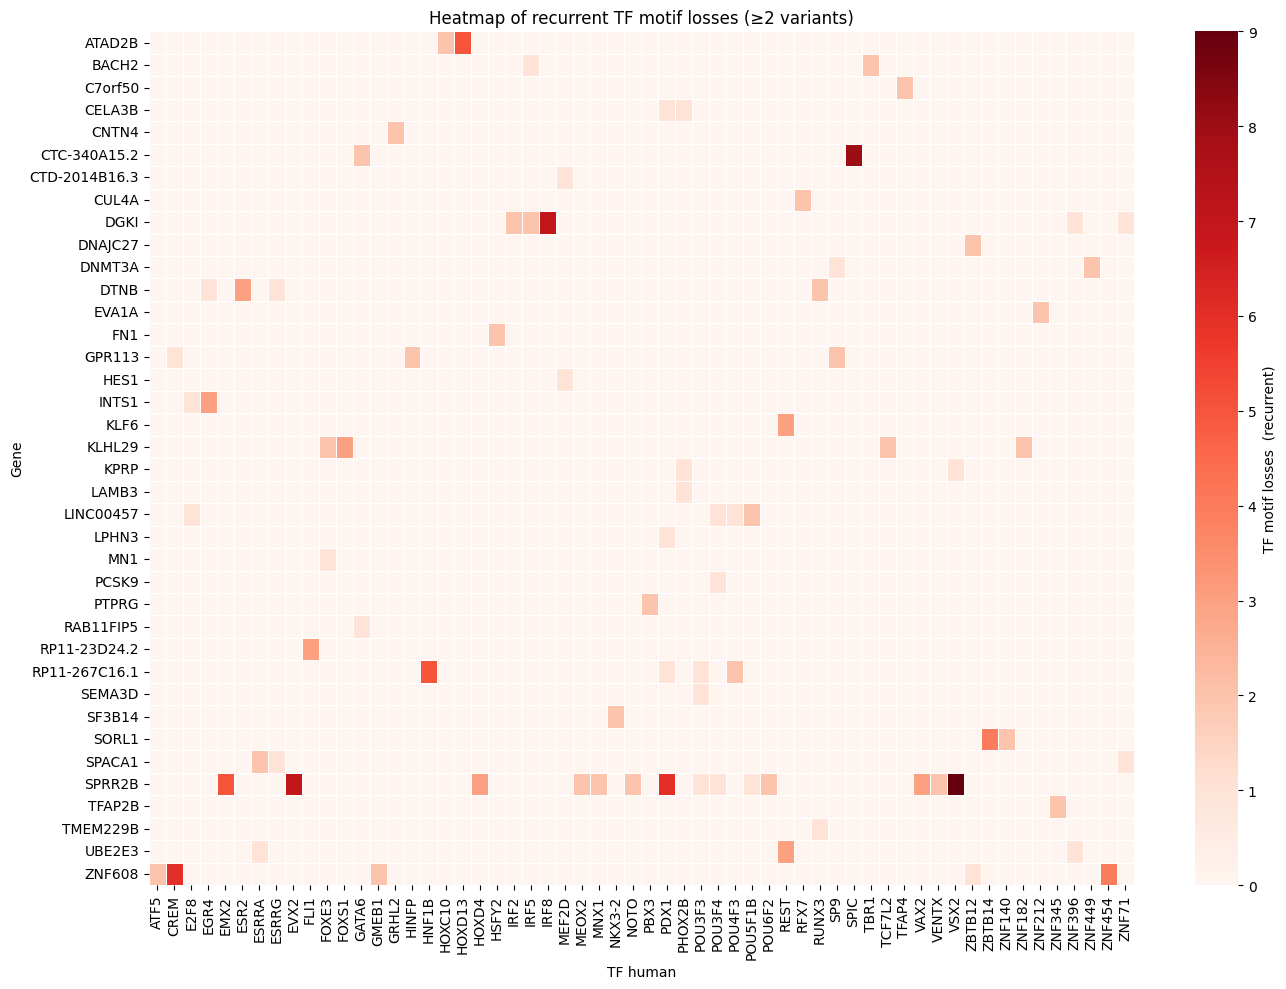

In [118]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))
sns.heatmap(
    lost_recurrent_matrix,
    cmap="Reds",
    linewidths=0.5,
    cbar_kws={"label": "TF motif losses  (recurrent)"}
)
plt.title("Heatmap of recurrent TF motif losses (≥2 variants)")
plt.xlabel("TF human")
plt.ylabel("Gene")
plt.tight_layout()
plt.show()


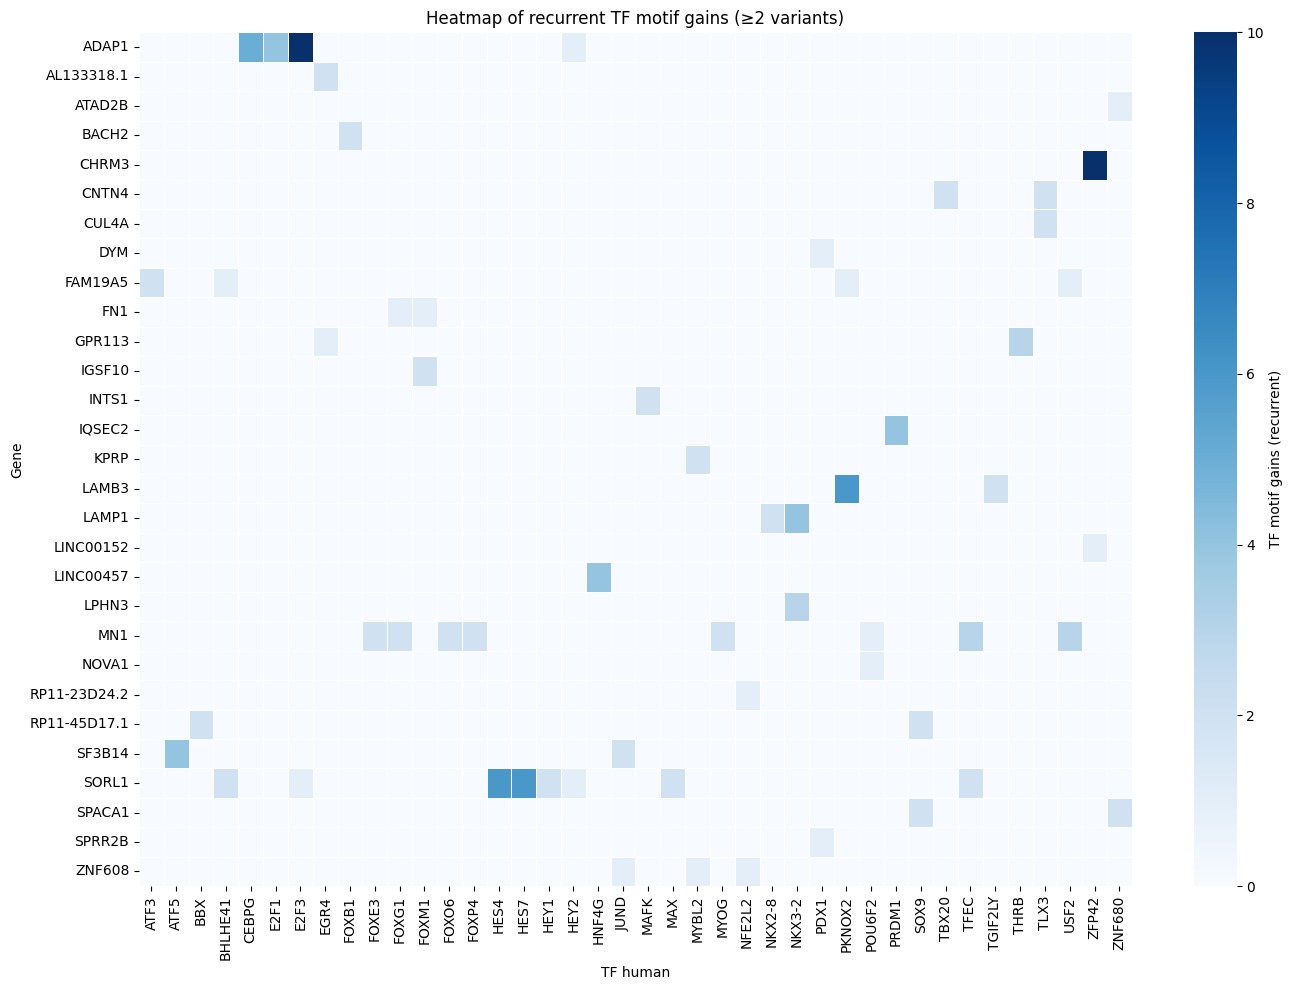

In [119]:
plt.figure(figsize=(14, 10))
sns.heatmap(
    gained_recurrent_matrix,
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "TF motif gains (recurrent)"}
)
plt.title("Heatmap of recurrent TF motif gains (≥2 variants)")
plt.xlabel("TF human")
plt.ylabel("Gene")
plt.tight_layout()
plt.show()


In [120]:
recurrent_gained

Index(['E2F3', 'ZFP42', 'PKNOX2', 'NKX3-2', 'HES7', 'HES4', 'TFEC', 'CEBPG',
       'HNF4G', 'SOX9', 'PRDM1', 'ATF5', 'TLX3', 'USF2', 'E2F1', 'THRB',
       'EGR4', 'FOXM1', 'JUND', 'MYBL2', 'ZNF680', 'FOXG1', 'BHLHE41', 'HEY2',
       'MAFK', 'FOXO6', 'PDX1', 'BBX', 'NKX2-8', 'NFE2L2', 'ATF3', 'TBX20',
       'FOXP4', 'MAX', 'FOXE3', 'MYOG', 'HEY1', 'POU6F2', 'TGIF2LY', 'FOXB1'],
      dtype='object', name='TF')

In [123]:
import re

def extract_family(tf):
    # delete digits at the end
    
    return re.sub(r"[\d-]+$", "", tf)

Tfgs = recurrent_gained.unique()
Tfls = recurrent_lost.unique()

# concaténer proprement
Tfs = list(Tfgs) + list(Tfls)

# dictionnaire TF → famille
tf_family_dict = {tf: extract_family(tf) for tf in Tfs}

#tf_family_dict


In [195]:
tf_family_dict

{'E2F3': 'E2F',
 'ZFP42': 'ZFP',
 'PKNOX2': 'PKNOX',
 'NKX3-2': 'NKX',
 'HES7': 'HES',
 'HES4': 'HES',
 'TFEC': 'TFEC',
 'CEBPG': 'CEBPG',
 'HNF4G': 'HNF4G',
 'SOX9': 'SOX',
 'PRDM1': 'PRDM',
 'ATF5': 'ATF',
 'TLX3': 'TLX',
 'USF2': 'USF',
 'E2F1': 'E2F',
 'THRB': 'THRB',
 'EGR4': 'EGR',
 'FOXM1': 'FOXM',
 'JUND': 'JUND',
 'MYBL2': 'MYBL',
 'ZNF680': 'ZNF',
 'FOXG1': 'FOXG',
 'BHLHE41': 'BHLHE',
 'HEY2': 'HEY',
 'MAFK': 'MAFK',
 'FOXO6': 'FOXO',
 'PDX1': 'PDX',
 'BBX': 'BBX',
 'NKX2-8': 'NKX',
 'NFE2L2': 'NFE2L',
 'ATF3': 'ATF',
 'TBX20': 'TBX',
 'FOXP4': 'FOXP',
 'MAX': 'MAX',
 'FOXE3': 'FOXE',
 'MYOG': 'MYOG',
 'HEY1': 'HEY',
 'POU6F2': 'POU6F',
 'TGIF2LY': 'TGIF2LY',
 'FOXB1': 'FOXB',
 'VSX2': 'VSX',
 'SPIC': 'SPIC',
 'IRF8': 'IRF',
 'EVX2': 'EVX',
 'CREM': 'CREM',
 'REST': 'REST',
 'HNF1B': 'HNF1B',
 'HOXD13': 'HOXD',
 'EMX2': 'EMX',
 'ZBTB14': 'ZBTB',
 'ZNF454': 'ZNF',
 'PHOX2B': 'PHOX2B',
 'FOXS1': 'FOXS',
 'POU3F3': 'POU3F',
 'RUNX3': 'RUNX',
 'SP9': 'SP',
 'ESR2': 'ESR',
 'GATA

In [125]:
recurrent_gained= pd.read_csv('/Volumes/mac1/data/limb/recurrent_gained.csv')
recurrent_lost= pd.read_csv('/Volumes/mac1/data/limb/recurrent_lost.csv')

In [126]:
lost_all["family"] = lost_all["TF"].apply(lambda tf: tf_family_dict.get(tf, tf))
gained_all["family"] = gained_all["TF"].apply(lambda tf: tf_family_dict.get(tf, tf))
lost_family_matrix = (
    lost_all.groupby(["gene", "family"])
            .size()
            .unstack(fill_value=0)
)
gained_family_matrix = (
    gained_all.groupby(["gene", "family"])
              .size()
              .unstack(fill_value=0)
)


In [128]:
gained_recurrent_matrix = (
    gained_all[gained_all["TF"].isin(recurrent_gained.TF)]
    .groupby(["gene", "family"])
    .size()
    .unstack(fill_value=0)
)

lost_recurrent_matrix = (
    lost_all[lost_all["TF"].isin(recurrent_lost.TF)]
    .groupby(["gene", "family"])
    .size()
    .unstack(fill_value=0)
)


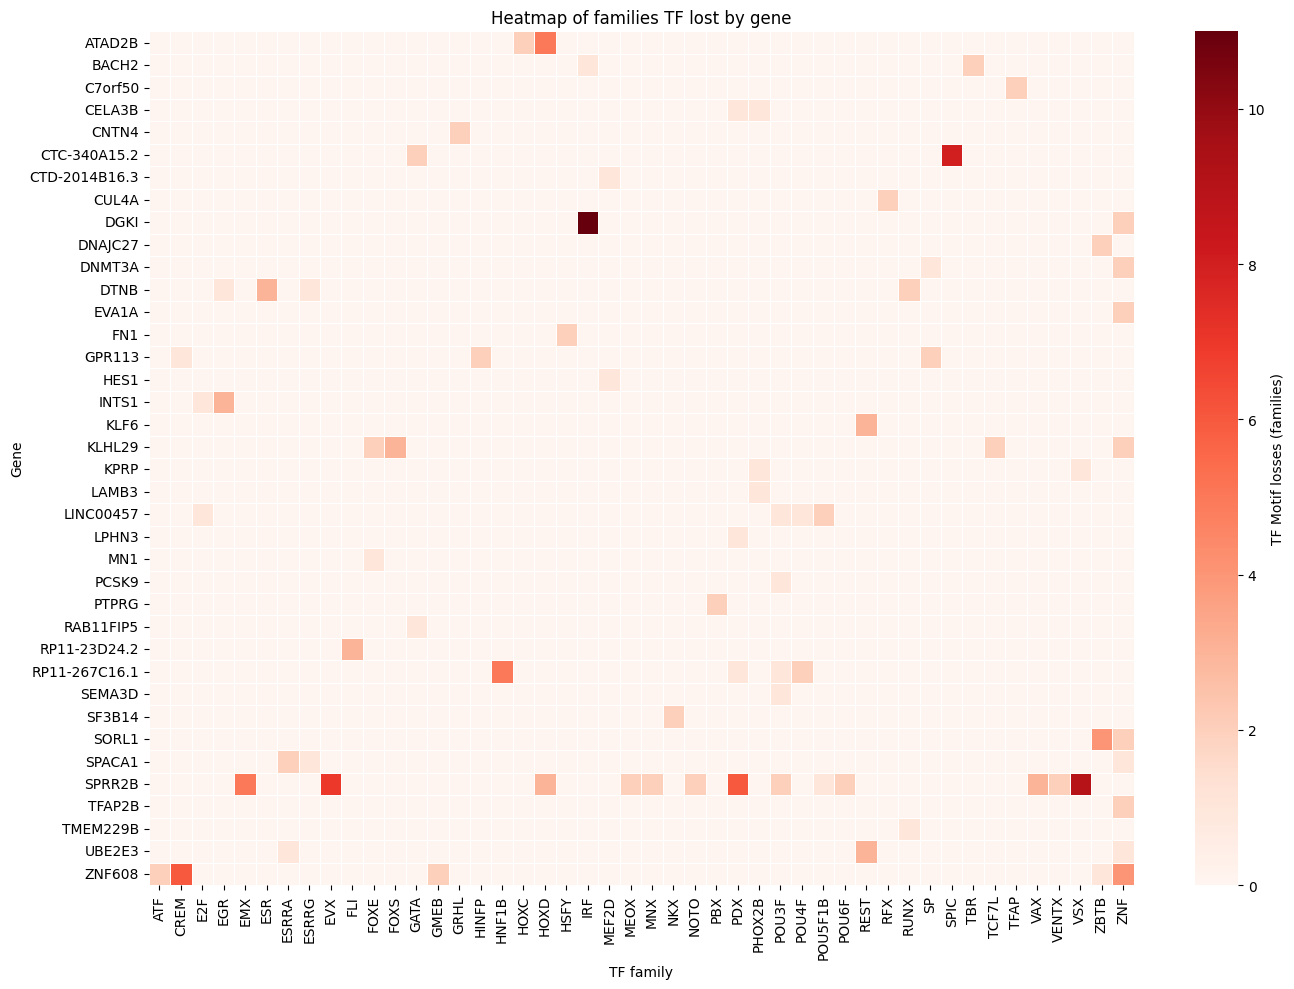

In [129]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))
sns.heatmap(
    lost_recurrent_matrix,
    cmap="Reds",
    linewidths=0.5,
    cbar_kws={"label": "TF Motif losses (families)"}
)
plt.title("Heatmap of families TF lost by gene")
plt.xlabel("TF family")
plt.ylabel("Gene")
plt.tight_layout()
plt.show()


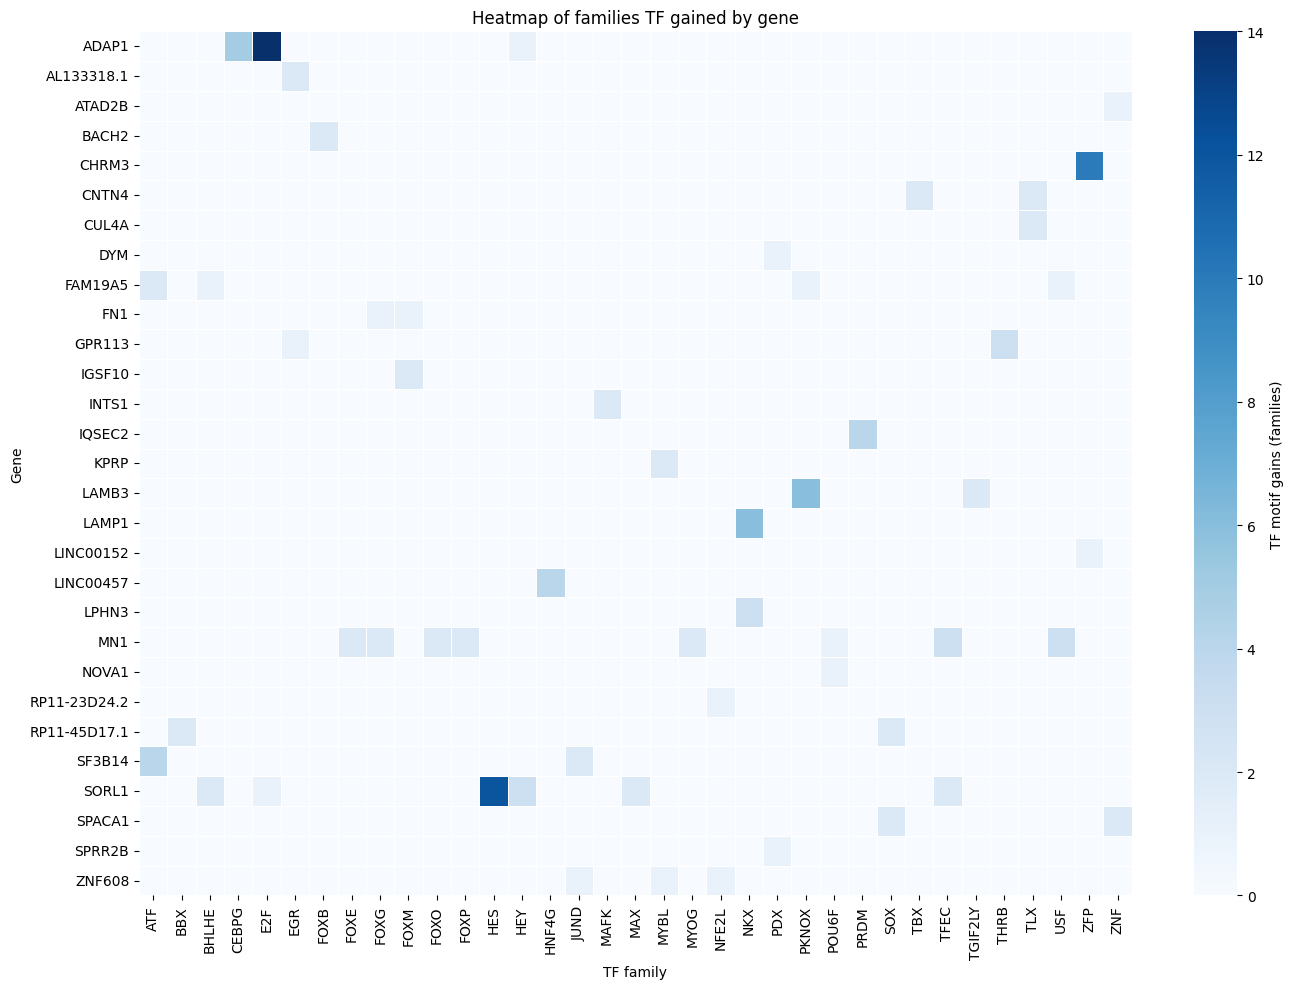

In [130]:
plt.figure(figsize=(14, 10))
sns.heatmap(
    gained_recurrent_matrix,
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "TF motif gains (families)"}
)
plt.title("Heatmap of families TF gained by gene")
plt.xlabel("TF family")
plt.ylabel("Gene")
plt.tight_layout()
plt.show()


In [131]:
top_genes = lost_family_matrix.sum(axis=1).sort_values(ascending=False).index.tolist()


In [132]:
genes_lost = lost_all[lost_all["TF"].isin(recurrent_lost)]["gene"].unique()
genes_gained = gained_all[gained_all["TF"].isin(recurrent_gained)]["gene"].unique()

genes_recurrent = list(set(genes_lost) | set(genes_gained))


In [133]:
combined_related = pd.read_csv('/Volumes/mac1/data/limb/df_allVariantWithGeneName.csv')
genes_variant = combined_related["GENE"].value_counts()
genes_variant = genes_variant.index.tolist()

In [134]:
genes_for_GO = list(set(genes_recurrent + genes_variant))


In [135]:
import gseapy as gp

go_results = gp.enrichr(
    gene_list=genes_for_GO,
    gene_sets="GO_Biological_Process_2021",
    organism="homo sapiens",
    outdir=None
)

go_df = go_results.results
limb_go = go_df[go_df["Term"].str.contains(
    "limb|foot|tendon|cartilage|skeletal|muscle|morphogenesis|axon",
    case=False
)]

In [136]:
limb_go.Term.unique()

array(['artery morphogenesis (GO:0048844)',
       'regulation of vascular associated smooth muscle contraction (GO:0003056)',
       'regulation of vascular associated smooth muscle cell differentiation (GO:1905063)',
       'hindlimb morphogenesis (GO:0035137)',
       'vascular associated smooth muscle cell development (GO:0097084)',
       'pharyngeal arch artery morphogenesis (GO:0061626)',
       'cell morphogenesis involved in differentiation (GO:0000904)',
       'negative regulation of vascular associated smooth muscle cell differentiation (GO:1905064)',
       'vascular associated smooth muscle cell differentiation (GO:0035886)',
       'vascular associated smooth muscle contraction (GO:0014829)',
       'negative regulation of smooth muscle cell differentiation (GO:0051151)',
       'forelimb morphogenesis (GO:0035136)',
       'axonal fasciculation (GO:0007413)',
       'smooth muscle contraction (GO:0006939)',
       'aorta morphogenesis (GO:0035909)',
       'negative reg

In [137]:
hpo_results = gp.enrichr(
    gene_list=genes_for_GO,
    gene_sets="Human_Phenotype_Ontology",
    organism="homo sapiens",
    outdir=None
)

hpo_df = hpo_results.results
limb_hpo = hpo_df[hpo_df["Term"].str.contains(
    "foot|limb|talus|club|gait|skeletal|deform",
    case=False
)]
#foot_hpo

kegg_results = gp.enrichr(
    gene_list=genes_for_GO,
    gene_sets="KEGG_2021_Human",
    organism="homo sapiens",
    outdir=None
)

kegg_df = kegg_results.results


In [138]:
hpo_df.Term.unique()

array(['Umbilical hernia (HP:0001537)', 'Pectus carinatum (HP:0000768)',
       'Abnormality of femoral epiphyses (HP:0006499)',
       'Congenital hip dislocation (HP:0001374)',
       'Abnormality involving the epiphyses of the lower limbs (HP:0006500)',
       'Blepharophimosis (HP:0000581)',
       'Abnormality of the acetabulum (HP:0003170)',
       'Lumbar hyperlordosis (HP:0002938)', 'Short neck (HP:0000470)',
       'Platyspondyly (HP:0000926)',
       'Everted lower lip vermilion (HP:0000232)',
       'Genu valgum (HP:0002857)',
       'Wrist flexion contracture (HP:0001239)', 'Volvulus (HP:0002580)',
       'Urethral obstruction (HP:0000796)',
       'Prostate neoplasm (HP:0100787)',
       'Carpal bone hypoplasia (HP:0001498)',
       'Depressed nasal ridge (HP:0000457)',
       'Stomach cancer (HP:0012126)', 'Protrusio acetabuli (HP:0003179)',
       'Onycholysis (HP:0001806)', 'Flat acetabular roof (HP:0003180)',
       'Attention deficit hyperactivity disorder (HP:0007018

In [139]:
kegg_df.Term.unique()

array(['ECM-receptor interaction', 'Small cell lung cancer',
       'Phosphatidylinositol signaling system', 'Amoebiasis',
       'Pancreatic secretion', 'Yersinia infection',
       'Ubiquitin mediated proteolysis',
       'Maturity onset diabetes of the young', 'Folate biosynthesis',
       'Human papillomavirus infection', 'Hepatitis B', 'Axon guidance',
       'Focal adhesion', 'Proteoglycans in cancer',
       'Nucleotide excision repair',
       'Human immunodeficiency virus 1 infection',
       'Cholesterol metabolism', 'Cysteine and methionine metabolism',
       'Regulation of actin cytoskeleton', 'Fanconi anemia pathway',
       'VEGF signaling pathway', 'Notch signaling pathway',
       'Glycerolipid metabolism', 'Endocytosis', 'Retinol metabolism',
       'Inositol phosphate metabolism', 'Gastric acid secretion',
       'Bacterial invasion of epithelial cells',
       'B cell receptor signaling pathway', 'Pathways in cancer',
       'Insulin secretion', 'Taste transduction'

analyse des TFs

In [140]:
import pandas as pd
gained_all = pd.read_csv('/Volumes/mac1/data/limb/gained_all.csv')
lost_all = pd.read_csv('/Volumes/mac1/data/limb/lost_all.csv')

In [141]:
gainTF = list(gained_all.TF)
lostTF = list(lost_all.TF)
allTF = list(set(gainTF).union(set(lostTF)))


In [100]:
import gseapy as gp

go_tf = gp.enrichr(
    gene_list=allTF,
    gene_sets="GO_Biological_Process_2021",
    organism="homo sapiens",
    outdir=None
)

go_tf_df = go_tf.results

go_tf_df[["Term", "Genes", "P-value"]].head()
go_tf_df.to_csv('/Volumes/mac1/data/limb/go_tf_df.csv', index=False)
import pandas as pd

# Filtrer les phénotypes significatifs
significant_go_tf = go_tf_df[go_tf_df["Adjusted P-value"] < 0.05]

# Afficher
print(significant_go_tf[["Term", "Adjusted P-value", "Genes"]])
significant_go_tf.to_csv('/Volumes/mac1/data/limb/significant_go_tf.csv', index=False)


                                                  Term  Adjusted P-value  \
0    regulation of transcription, DNA-templated (GO...     1.704837e-226   
1    regulation of transcription by RNA polymerase ...     4.864895e-219   
2    positive regulation of transcription, DNA-temp...      6.178159e-66   
3    positive regulation of transcription by RNA po...      1.835589e-60   
4    negative regulation of transcription, DNA-temp...      4.621498e-51   
..                                                 ...               ...   
221    enteric nervous system development (GO:0048484)      4.867574e-02   
222  positive regulation of chondrocyte differentia...      4.867574e-02   
223    metanephric mesenchyme development (GO:0072075)      4.867574e-02   
224                        vasculogenesis (GO:0001570)      4.916161e-02   
225      cell cycle G1/S phase transition (GO:0044843)      4.930475e-02   

                                                 Genes  
0    ATF2;ZNF175;SPI1;FOXI1;IK

In [150]:
hpo_tf = gp.enrichr(
    gene_list=allTF,
    gene_sets="Human_Phenotype_Ontology",
    organism="homo sapiens",
    outdir=None
)

hpo_tf_df = hpo_tf.results
hpo_tf_df.to_csv('/Volumes/mac1/data/limb/hpo_tf_df.csv', index=False)


In [153]:
import pandas as pd

# Load your HPO enrichment table
df = pd.read_csv("/Volumes/mac1/data/limb/hpo_tf_df.csv")

# --- Dual-filter strategy ---
# Tier 1: High-confidence terms (FDR < 0.05)
tier1 = df[df["Adjusted P-value"] < 0.05]

# Tier 2: Medium-confidence TF-specific terms
tier2 = df[(df["Odds Ratio"] > 3.4) | (df["Combined Score"] > 4.5)]

# Combine tiers (remove duplicates)
best_terms = pd.concat([tier1, tier2]).drop_duplicates()

# Sort by Combined Score (optional)
best_terms = best_terms.sort_values("Combined Score", ascending=False)

# Save results
best_terms.to_csv("best_hpo_terms.csv", index=False)

print("Extracted best HPO terms using dual-filter strategy:")
print(best_terms[["Term", "Adjusted P-value", "Odds Ratio", "Combined Score"]])


Extracted best HPO terms using dual-filter strategy:
                                                  Term  Adjusted P-value  \
4    Morphological abnormality of the inner ear (HP...          0.034343   
5                  Abnormal pancreas size (HP:0012094)          0.034343   
8                       Ureteral stenosis (HP:0000071)          0.049109   
1                           Bifid scrotum (HP:0000048)          0.034343   
22                           Concave nail (HP:0001598)          0.119014   
..                                                 ...               ...   
454                              Drooling (HP:0002307)          0.386208   
455                         Hemivertebrae (HP:0002937)          0.386208   
456                            Cupped ear (HP:0000378)          0.386208   
457  Abnormal autonomic nervous system physiology (...          0.386208   
458                  Cutaneous syndactyly (HP:0012725)          0.386208   

     Odds Ratio  Combined Score  


In [194]:
import pronto

#hpo = pronto.Ontology("https://raw.githubusercontent.com/obophenotype/human-phenotype-ontology/master/hp.obo")

def get_parents(hpo_id):
    term = hpo[hpo_id]
    return [parent.name for parent in term.superclasses()]

print(get_parents("HP:0000071"))
best_terms = pd.read_csv("best_hpo_terms.csv")
best_terms['Parents'] = best_terms['Term'].apply(lambda term: get_parents(term.split('(')[1].rstrip(')')) if pd.notnull(term) else [])
best_terms.to_csv("best_hpo_terms_with_parents.csv", index=False)
best_terms[['Parents','Term']].head()


['Ureteral stenosis', 'Ureteral obstruction', 'Abnormal ureter physiology', 'Abnormality of the ureter', 'Abnormality of the upper urinary tract', 'Abnormality of the urinary system', 'Abnormality of the genitourinary system', 'Phenotypic abnormality', 'All']


,Parents,Term
0,"[Abnormal inner ear morphology, Abnormality of...",Morphological abnormality of the inner ear (HP...
1,"[Abnormal pancreas size, Abnormal pancreas mor...",Abnormal pancreas size (HP:0012094)
2,"[Ureteral stenosis, Ureteral obstruction, Abno...",Ureteral stenosis (HP:0000071)
3,"[Bifid scrotum, Abnormal scrotum morphology, A...",Bifid scrotum (HP:0000048)
4,"[Concave nail, Nail dysplasia, Abnormal nail m...",Concave nail (HP:0001598)


In [ ]:
for parent in best_terms['Parents'].explode():
    print(parent)

Abnormal inner ear morphology
Abnormality of the inner ear
Abnormal ear morphology
Abnormality of the ear
Phenotypic abnormality
All
Abnormal pancreas size
Abnormal pancreas morphology
Abnormality of the pancreas
Abnormality of the abdominal organs
Abnormality of the digestive system
Phenotypic abnormality
All
Ureteral stenosis
Ureteral obstruction
Abnormal ureter physiology
Abnormality of the ureter
Abnormality of the upper urinary tract
Abnormality of the urinary system
Abnormality of the genitourinary system
Phenotypic abnormality
All
Bifid scrotum
Abnormal scrotum morphology
Abnormal male external genitalia morphology
Abnormal external genitalia morphology
Abnormality of the male genitalia
Abnormal reproductive system morphology
Abnormality of the genital system
Abnormality of the genitourinary system
Phenotypic abnormality
All
Concave nail
Nail dysplasia
Abnormal nail morphology
Abnormal skin adnexa morphology
Abnormality of the integument
Phenotypic abnormality
All
Septate vagina

In [193]:
np.unique([parent[-3] for parent in best_terms['Parents'] if len(parent) > 6])

array(['Abnormal anterior eye segment morphology',
       'Abnormal digestive system morphology', 'Abnormal eye morphology',
       'Abnormal homeostasis', 'Abnormal musculoskeletal physiology',
       'Abnormal nervous system morphology',
       'Abnormal posterior eye segment morphology',
       'Abnormal reproductive system morphology',
       'Abnormal skeletal morphology', 'Abnormal skin adnexa morphology',
       'Abnormality of blood and blood-forming tissues',
       'Abnormality of head or neck', 'Abnormality of limbs',
       'Abnormality of metabolism/homeostasis',
       'Abnormality of the cardiovascular system',
       'Abnormality of the digestive system', 'Abnormality of the ear',
       'Abnormality of the endocrine system', 'Abnormality of the eye',
       'Abnormality of the face',
       'Abnormality of the genitourinary system',
       'Abnormality of the head', 'Abnormality of the immune system',
       'Abnormality of the integument', 'Abnormality of the musculat

In [183]:
np.unique([int(l) for l,p in lengths])

array([ 1,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18,
       19, 20, 21, 22, 23, 25, 26, 28, 29, 30, 38, 39])

In [42]:
from goatools.obo_parser import GODag
go_dag = GODag("/Volumes/mac1/data/feet/go-basic.obo")


/Volumes/mac1/data/feet/go-basic.obo: fmt(1.2) rel(2026-07-26) 41,378 Terms


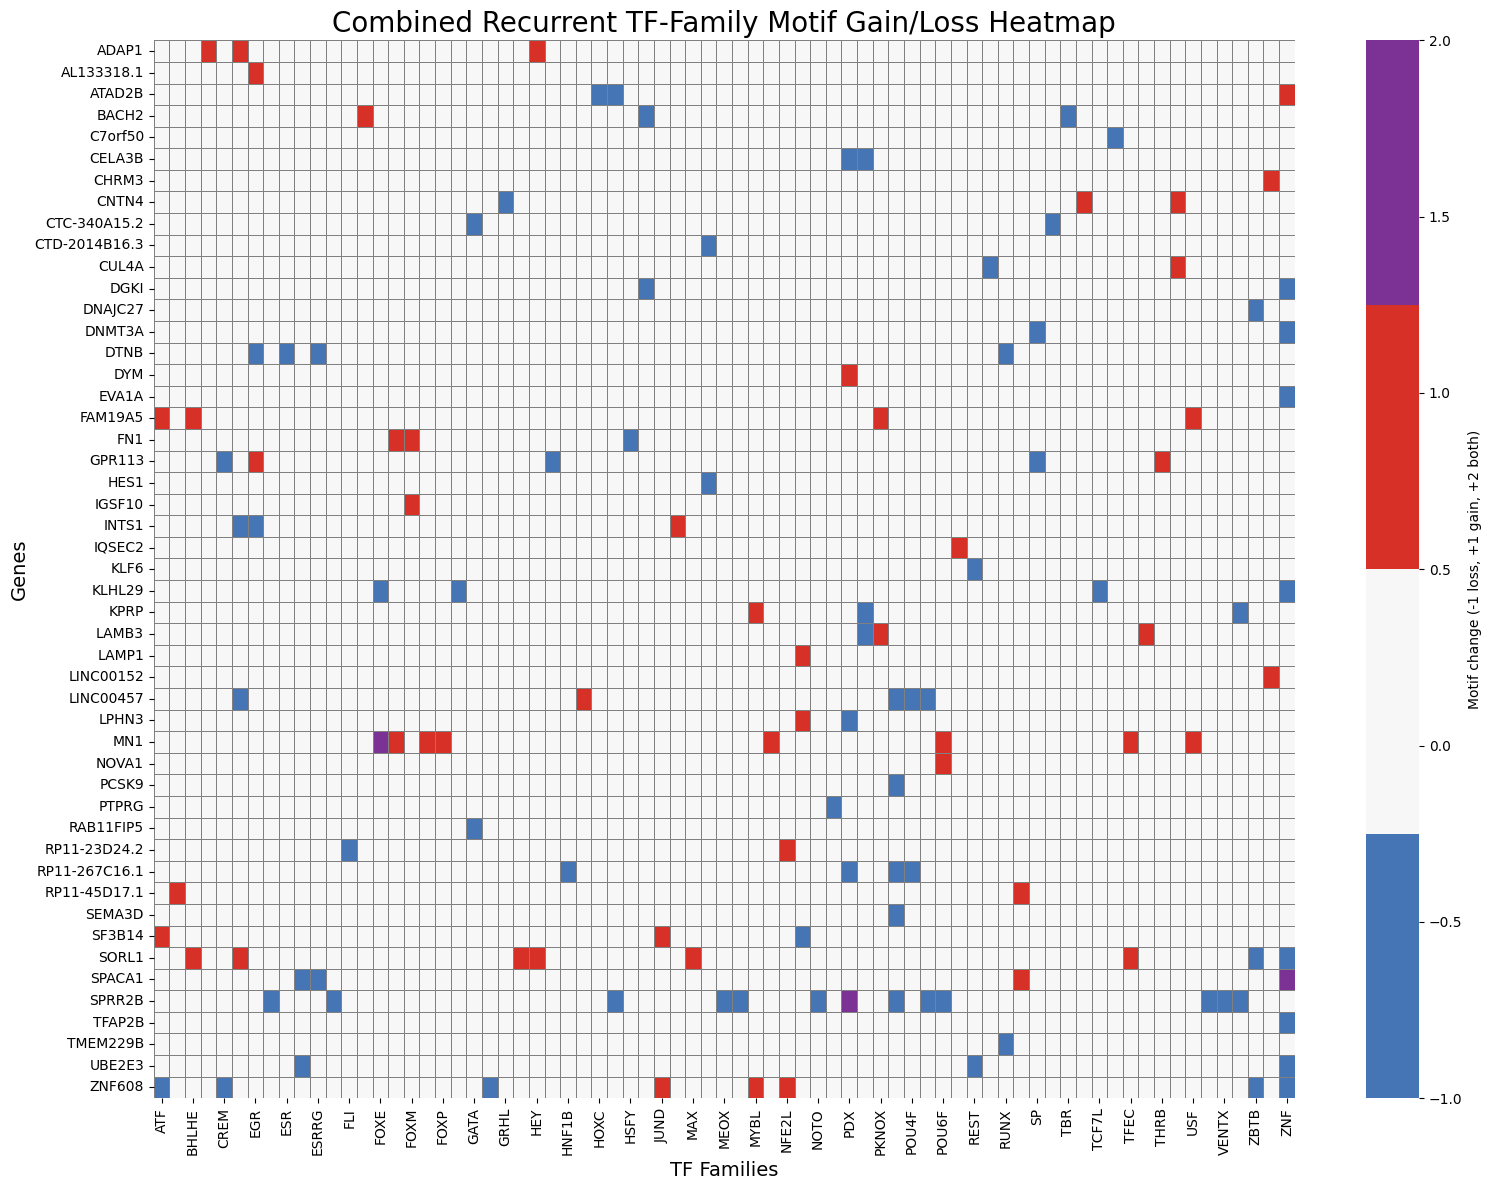

In [142]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------------------------------------------------
# 1. Align matrices (same genes, same TF families)
# ---------------------------------------------------
lost = lost_recurrent_matrix.copy()
gain = gained_recurrent_matrix.copy()

all_genes = sorted(set(lost.index) | set(gain.index))
all_families = sorted(set(lost.columns) | set(gain.columns))

lost = lost.reindex(index=all_genes, columns=all_families, fill_value=0)
gain = gain.reindex(index=all_genes, columns=all_families, fill_value=0)

# ---------------------------------------------------
# 2. Build combined matrix
# ---------------------------------------------------
combined = pd.DataFrame(0, index=all_genes, columns=all_families)

# Loss only = -1
combined[lost > 0] = -1

# Gain only = +1
combined[gain > 0] = 1

# Both gain & loss = +2
combined[(lost > 0) & (gain > 0)] = 2

# ---------------------------------------------------
# 3. Plot heatmap
# ---------------------------------------------------
plt.figure(figsize=(16, 12))

# Color map:
# -1 = blue (loss)
#  0 = white (none)
# +1 = red (gain)
# +2 = purple (gain+loss)
cmap = ListedColormap([
    "#4575b4",  # -1 loss
    "#f7f7f7",  # 0 none
    "#d73027",  # +1 gain
    "#7b3294"   # +2 both
])

sns.heatmap(
    combined,
    cmap=cmap,
    linewidths=0.4,
    linecolor="gray",
    cbar_kws={"label": "Motif change (-1 loss, +1 gain, +2 both)"}
)

plt.title("Combined Recurrent TF-Family Motif Gain/Loss Heatmap", fontsize=20)
plt.xlabel("TF Families", fontsize=14)
plt.ylabel("Genes", fontsize=14)
plt.tight_layout()
plt.show()


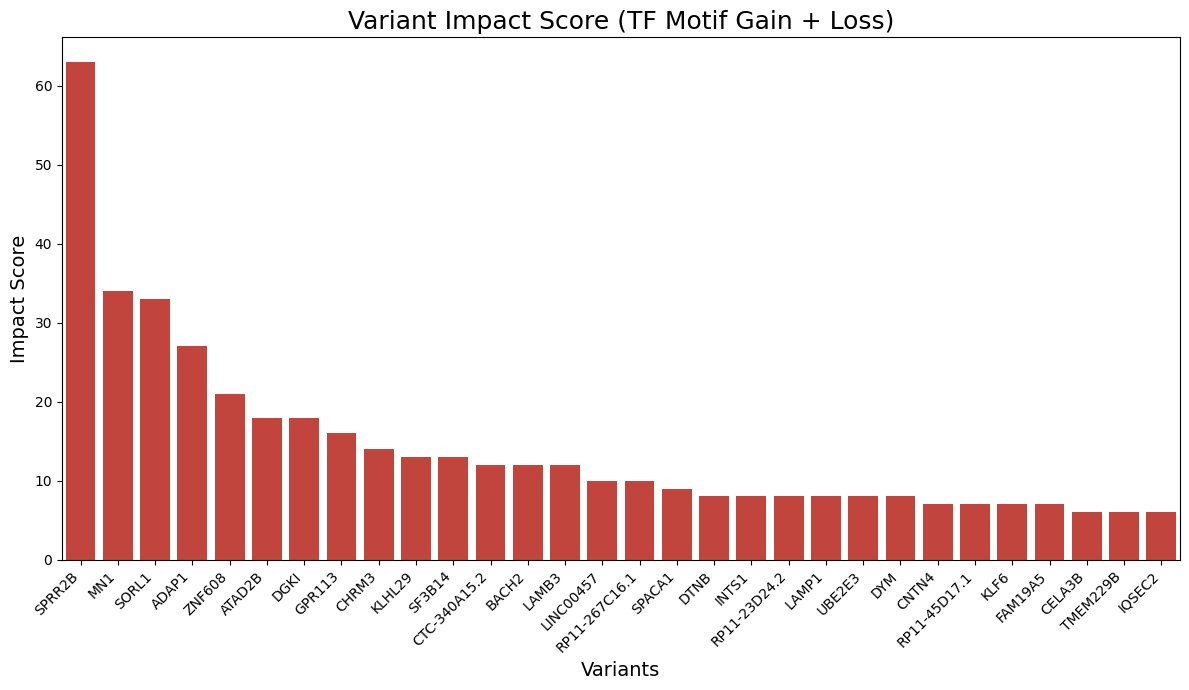

In [143]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------
# 1. Count motif gains and losses per variant
# ---------------------------------------------------
gain_counts = (
    gained_all.groupby("gene")
              .size()
              .rename("gain")
)

loss_counts = (
    lost_all.groupby("gene")
            .size()
            .rename("loss")
)

# Combine
variant_scores = pd.concat([gain_counts, loss_counts], axis=1).fillna(0)

# Impact score = gain + loss
variant_scores["impact_score"] = variant_scores["gain"] + variant_scores["loss"]

# Sort by impact
variant_scores = variant_scores.sort_values("impact_score", ascending=False).head(30)

# ---------------------------------------------------
# 2. Plot
# ---------------------------------------------------
plt.figure(figsize=(12, 7))

sns.barplot(
    data=variant_scores.reset_index(),
    x="gene",
    y="impact_score",
    color="#d73027"
)

plt.title("Variant Impact Score (TF Motif Gain + Loss)", fontsize=18)
plt.xlabel("Variants", fontsize=14)
plt.ylabel("Impact Score", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [124]:
tf_family_dict

{'E2F3': 'E2F',
 'ZFP42': 'ZFP',
 'PKNOX2': 'PKNOX',
 'NKX3-2': 'NKX',
 'HES7': 'HES',
 'HES4': 'HES',
 'TFEC': 'TFEC',
 'CEBPG': 'CEBPG',
 'HNF4G': 'HNF4G',
 'SOX9': 'SOX',
 'PRDM1': 'PRDM',
 'ATF5': 'ATF',
 'TLX3': 'TLX',
 'USF2': 'USF',
 'E2F1': 'E2F',
 'THRB': 'THRB',
 'EGR4': 'EGR',
 'FOXM1': 'FOXM',
 'JUND': 'JUND',
 'MYBL2': 'MYBL',
 'ZNF680': 'ZNF',
 'FOXG1': 'FOXG',
 'BHLHE41': 'BHLHE',
 'HEY2': 'HEY',
 'MAFK': 'MAFK',
 'FOXO6': 'FOXO',
 'PDX1': 'PDX',
 'BBX': 'BBX',
 'NKX2-8': 'NKX',
 'NFE2L2': 'NFE2L',
 'ATF3': 'ATF',
 'TBX20': 'TBX',
 'FOXP4': 'FOXP',
 'MAX': 'MAX',
 'FOXE3': 'FOXE',
 'MYOG': 'MYOG',
 'HEY1': 'HEY',
 'POU6F2': 'POU6F',
 'TGIF2LY': 'TGIF2LY',
 'FOXB1': 'FOXB',
 'VSX2': 'VSX',
 'SPIC': 'SPIC',
 'IRF8': 'IRF',
 'EVX2': 'EVX',
 'CREM': 'CREM',
 'REST': 'REST',
 'HNF1B': 'HNF1B',
 'HOXD13': 'HOXD',
 'EMX2': 'EMX',
 'ZBTB14': 'ZBTB',
 'ZNF454': 'ZNF',
 'PHOX2B': 'PHOX2B',
 'FOXS1': 'FOXS',
 'POU3F3': 'POU3F',
 'RUNX3': 'RUNX',
 'SP9': 'SP',
 'ESR2': 'ESR',
 'GATA

<Figure size 1200x800 with 0 Axes>

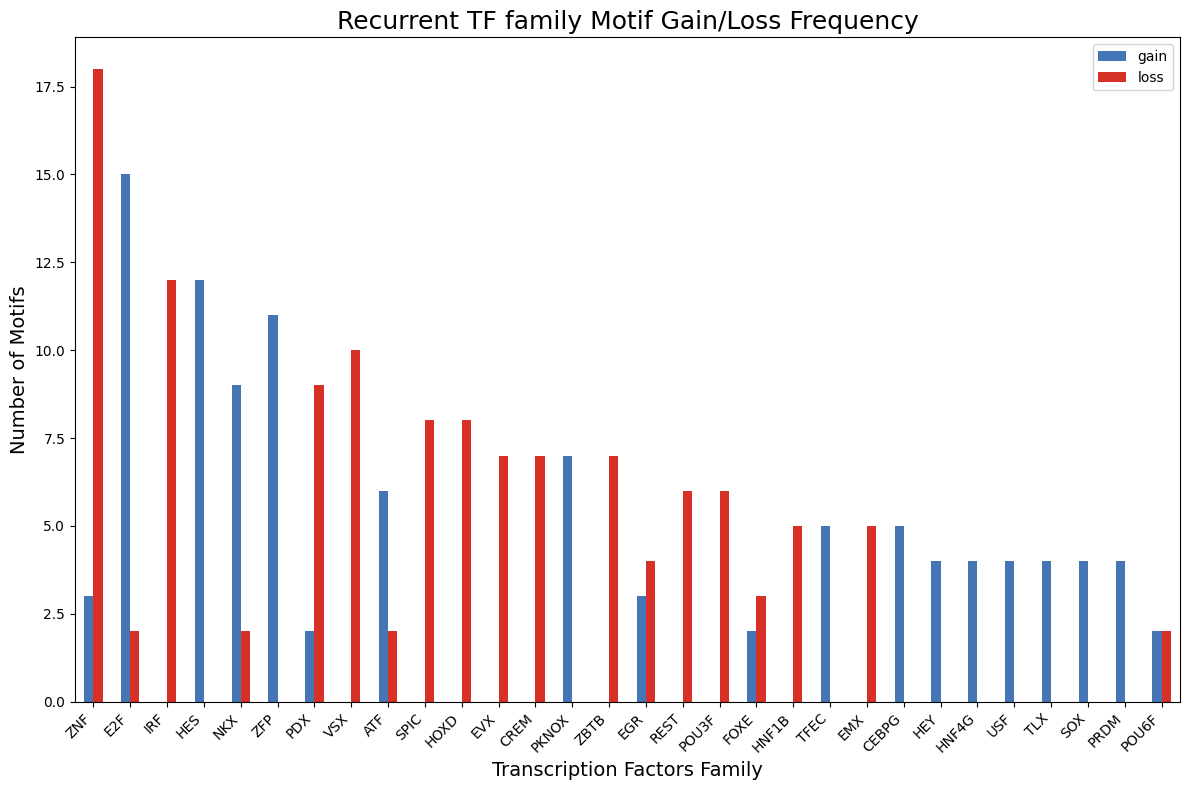

In [146]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------
# 1. Count recurrence for each TF
# ---------------------------------------------------

lost_all["family"] = lost_all["TF"].apply(lambda tf: tf_family_dict.get(tf, tf))

gained_all['family'] = gained_all['TF'].apply(lambda tf: tf_family_dict.get(tf, tf))

gain_counts = (
    gained_all[gained_all["TF"].isin(recurrent_gained.TF)]
    .groupby("family")
    .size()
    .rename("gain")
)

loss_counts = (
    lost_all[lost_all["TF"].isin(recurrent_lost.TF)]
    .groupby("family")
    .size()
    .rename("loss")
)

# Combine into one DataFrame
tf_counts = pd.concat([gain_counts, loss_counts], axis=1).fillna(0)

# Sort by total recurrence
tf_counts["total"] = tf_counts["gain"] + tf_counts["loss"]
tf_counts = tf_counts.sort_values("total", ascending=False).head(30)

# ---------------------------------------------------
# 2. Plot barplot
# ---------------------------------------------------
plt.figure(figsize=(12, 8))

tf_counts[["gain", "loss"]].plot(
    kind="bar",
    stacked=False,
    color=[ "#4575b4", "#d73027"],  # blue gain, red loss
    figsize=(12, 8)
)

plt.title("Recurrent TF family Motif Gain/Loss Frequency", fontsize=18)
plt.ylabel("Number of Motifs", fontsize=14)
plt.xlabel("Transcription Factors Family", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
